# Notebook 2 · Modelo B: Transfer learning con MobileNetV2 (SMILES)
Mismo dataset, **mismo split** (semilla 42) y **mismo contrato de entrada** que el Modelo A: la app local puede cambiar de modelo con solo `--model model_B_mobilenetv2.keras --metrics B_metrics.json`.

Dentro del modelo: la imagen gris de 64x64 se amplía a 96x96, se replica a 3 canales y se normaliza a [-1, 1], que es lo que espera MobileNetV2.

**Entrenamiento en 2 fases:** (1) solo la cabeza con la base congelada; (2) fine-tuning de las últimas capas con tasa de aprendizaje baja.

**IMPORTANTE:** activa **Internet** en Session options (barra lateral derecha) para descargar los pesos de ImageNet. Activa también la **GPU**.
Primero corre con `QUICK_TEST = True` para depurar.

In [1]:
# ==============================================================================
# 1. Configuración, librerías y constantes globales (Modelo B - Transfer Learning)
# ==============================================================================
# Utiliza MobileNetV2 preentrenada en ImageNet como extractor de características base.
# Adapta la entrada (64x64 gris) al formato requerido por la base (96x96, 3 canales, [-1, 1]).
import os, glob, json, time, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, roc_auc_score)

QUICK_TEST = False          # <- False para el entrenamiento real completo

SEED = 42
IMG_SIZE = 64              # contrato con la app (no cambiar: entrada 64x64)
INPUT_B = 96               # tamaño interno mínimo recomendado para MobileNetV2
BATCH = 64
EPOCHS_HEAD = 1 if QUICK_TEST else 12    # Fase 1: solo la cabeza clasificadora
EPOCHS_FINE = 1 if QUICK_TEST else 20    # Fase 2: ajuste fino de capas superiores
N_UNFREEZE = 30            # últimas capas de la base que se descongelan en Fase 2

BASE    = "/kaggle/input/datasets/marcos03/smiles/SMILEs"
POS_DIR = f"{BASE}/positives/positives7"
NEG_DIR = f"{BASE}/negatives/negatives7"
OUT     = "/kaggle/working"

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Carga y split (idéntico al Modelo A)

In [2]:
# ==============================================================================
# 2. Carga de datos, partición estratificada y ponderación de clases
# ==============================================================================
# Se mantiene el mismo preprocesamiento y partición estratificada que en Modelo A
# para garantizar una comparación rigurosa y no sesgada entre arquitecturas.
# compute_class_weight("balanced") compensa la menor frecuencia de la clase 'sonríe'.
def list_images(folder):
    return sorted(glob.glob(os.path.join(folder, "*.jpg")))

pos_paths = list_images(POS_DIR); neg_paths = list_images(NEG_DIR)
print("positivas:", len(pos_paths), "| negativas:", len(neg_paths))
assert len(pos_paths) > 0 and len(neg_paths) > 0, "Revisa las rutas"

def load_images(paths):
    arr = [np.array(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE))) for p in paths]
    return np.stack(arr).astype("float32")[..., None]

X = np.concatenate([load_images(neg_paths), load_images(pos_paths)])
y = np.concatenate([np.zeros(len(neg_paths)), np.ones(len(pos_paths))]).astype("float32")

# División estratificada: 70% Train, 15% Val, 15% Test
idx = np.arange(len(y))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)
X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]
print("train:", len(y_train), "| val:", len(y_val), "| test:", len(y_test))

# --- PESOS DE CLASE (class_weight) ---
# Asigna pesos balanceados para penalizar errores en la clase minoritaria (sonrisas)
cw = compute_class_weight("balanced", classes=np.array([0., 1.]), y=y_train)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("class_weight:", class_weight)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(len(y_train), seed=SEED).batch(BATCH).prefetch(AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH).prefetch(AUTOTUNE)


positivas: 3690 | negativas: 9475
train: 9215 | val: 1975 | test: 1975
class_weight: {0: 0.6947376357056695, 1: 1.783778552071235}


## 2. Modelo (MobileNetV2 preentrenada en ImageNet)

In [3]:
# ==============================================================================
# 3. Arquitectura del Modelo B: Transfer Learning con MobileNetV2
# ==============================================================================
# Pipeline arquitectónico:
#   1. Entrada estándar (64, 64, 1): mantiene el contrato de la aplicación.
#   2. Data Augmentation integrada: idéntica a Modelo A (flip, rotation, zoom, brillo, contraste).
#   3. Adaptación a MobileNetV2:
#      - Resizing(96, 96): resolución espacial mínima óptima para la base convolucional.
#      - Concatenate()([x, x, x]): triplica el canal de grises a 3 canales RGB idénticos.
#      - Rescaling(1/127.5, offset=-1.0): normaliza los valores [0, 255] a [-1.0, 1.0].
#   4. Base MobileNetV2 (pesos ImageNet, sin cabeza original include_top=False).
#      - Inicialmente congelada (base.trainable = False) para Feature Extraction.
#      - training=False en la llamada asegura que las capas BatchNormalization operen en inferencia.
#   5. Cabeza clasificadora personalizada: GlobalAveragePooling2D -> Dropout(0.3) -> Dense(1, sigmoid).
def build_model():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 1))
    # --- Data Augmentation (activa solo en entrenamiento) ---
    x = layers.RandomFlip("horizontal")(inp)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomBrightness(0.25, value_range=(0, 255))(x)
    x = layers.RandomContrast(0.25)(x)
    # --- Adaptación a los requisitos de entrada de MobileNetV2 ---
    x = layers.Resizing(INPUT_B, INPUT_B)(x)
    x = layers.Concatenate()([x, x, x])
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)
    try:
        base = keras.applications.MobileNetV2(input_shape=(INPUT_B, INPUT_B, 3),
                                              include_top=False, weights="imagenet")
    except Exception as e:
        raise RuntimeError("No se pudieron descargar los pesos de ImageNet. "
                           "Activa Internet en Session options.") from e
    # Congelación inicial de la base convolucional (Fase 1: Feature Extraction)
    base.trainable = False
    x = base(x, training=False)          # BatchNorm de la base en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="modelo_B_mobilenetv2"), base

model, base = build_model()
print("Parámetros totales:", f"{model.count_params():,}")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros totales: 2,259,265


## 3. Fase 1: entrenar solo la cabeza (base congelada)

In [4]:
# ==============================================================================
# 4. Fase 1: Entrenamiento de la cabeza clasificadora (Base congelada)
# ==============================================================================
# Se entrena únicamente la capa Dense(1) superior con Adam(1e-3).
# Callbacks:
# - EarlyStopping(patience=4, restore_best_weights=True): detiene si val_loss no mejora en 4 épocas.
# - ReduceLROnPlateau(patience=2, factor=0.5): reduce lr a la mitad tras 2 épocas de estancamiento.
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
      keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)]
t0 = time.time()
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                  class_weight=class_weight, callbacks=cb)


Epoch 1/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.6691 - auc: 0.7327 - loss: 0.6282 - val_accuracy: 0.7803 - val_auc: 0.8512 - val_loss: 0.4645 - learning_rate: 0.0010
Epoch 2/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7487 - auc: 0.8299 - loss: 0.5092 - val_accuracy: 0.7813 - val_auc: 0.8714 - val_loss: 0.4595 - learning_rate: 0.0010
Epoch 3/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7745 - auc: 0.8512 - loss: 0.4817 - val_accuracy: 0.8122 - val_auc: 0.8787 - val_loss: 0.4092 - learning_rate: 0.0010
Epoch 4/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.7831 - auc: 0.8593 - loss: 0.4684 - val_accuracy: 0.7484 - val_auc: 0.8839 - val_loss: 0.5004 - learning_rate: 0.0010
Epoch 5/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7862 - auc: 0.8637 - loss: 0.4625 - val_accuracy: 0.8228 - val_auc: 0.8863 - val_loss: 0.4001 - learning_rate: 0.0010
Epoch 6/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7991 - 

## 4. Fase 2: fine-tuning de las últimas capas (tasa de aprendizaje baja)

In [5]:
# ==============================================================================
# 5. Fase 2: Ajuste fino (Fine-Tuning) de las capas convolucionales superiores
# ==============================================================================
# Estrategia de Fine-Tuning:
#   1. Se descongela la base (base.trainable = True), pero se vuelven a congelar todas
#      las capas iniciales excepto las últimas N_UNFREEZE (30 capas más profundas).
#   2. Las capas BatchNormalization se mantienen CONGELADAS permanentemente para evitar
#      que los estadísticos de media y varianza se desestabilicen con batches pequeños.
#   3. Se recompila con un learning rate muy reducido (2e-5) para no destruir los pesos
#      preentrenados en ImageNet mientras se adaptan las características a la tarea de sonrisas.
#   4. Callbacks con mayor paciencia (EarlyStopping patience=6) para permitir convergencia suave.
base.trainable = True
for l in base.layers[:-N_UNFREEZE]:
    l.trainable = False
for l in base.layers:                       # BatchNorm siempre congelada: más estable con pocos datos
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
print("Capas entrenables de la base:", sum(l.trainable for l in base.layers))

model.compile(optimizer=keras.optimizers.Adam(2e-5), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
      keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)]
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE,
                  class_weight=class_weight, callbacks=cb)
train_minutes = (time.time() - t0) / 60
print(f"Tiempo total de entrenamiento: {train_minutes:.1f} min")


Capas entrenables de la base: 19
Epoch 1/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 14s 51ms/step - accuracy: 0.8027 - auc: 0.8813 - loss: 0.4340 - val_accuracy: 0.8527 - val_auc: 0.9203 - val_loss: 0.3535 - learning_rate: 2.0000e-05
Epoch 2/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.8354 - auc: 0.9128 - loss: 0.3761 - val_accuracy: 0.8820 - val_auc: 0.9321 - val_loss: 0.2874 - learning_rate: 2.0000e-05
Epoch 3/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.8534 - auc: 0.9287 - loss: 0.3402 - val_accuracy: 0.8810 - val_auc: 0.9369 - val_loss: 0.2945 - learning_rate: 2.0000e-05
Epoch 4/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.8626 - auc: 0.9347 - loss: 0.3264 - val_accuracy: 0.8825 - val_auc: 0.9419 - val_loss: 0.2787 - learning_rate: 2.0000e-05
Epoch 5/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.8652 - auc: 0.9396 - loss: 0.3145 - val_accuracy: 0.8932 - val_auc: 0.9442 - val_loss: 0.2645 - learning_rate: 2.0000e-05
Epoch 6/20
144/144 ━━

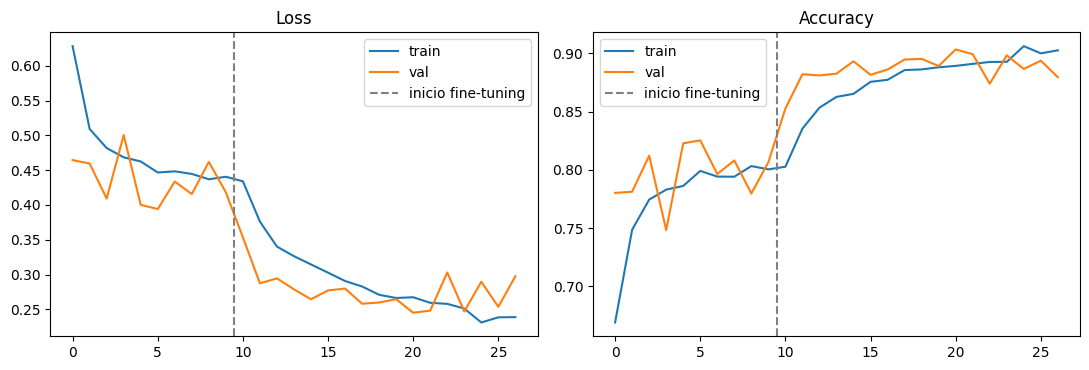

In [6]:
# ==============================================================================
# 6. Curvas completas de entrenamiento (Fase 1 Cabeza + Fase 2 Fine-Tuning)
# ==============================================================================
def cat(k): return hist1.history[k] + hist2.history[k]
split = len(hist1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, k, t in ((ax[0], "loss", "Loss"), (ax[1], "accuracy", "Accuracy")):
    a.plot(cat(k), label="train"); a.plot(cat("val_" + k), label="val")
    a.axvline(split - 0.5, color="gray", ls="--", label="inicio fine-tuning")
    a.set_title(t); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/B_curvas.png", dpi=130); plt.show()


## 5. Evaluación (mismo procedimiento que el Modelo A)

Mejor umbral (val): 0.51 | F1 val: 0.8261

===== TEST con umbral 0.50 =====
              precision    recall  f1-score   support

   no sonríe     0.9376    0.9402    0.9389      1422
      sonríe     0.8452    0.8391    0.8421       553

    accuracy                         0.9119      1975
   macro avg     0.8914    0.8896    0.8905      1975
weighted avg     0.9117    0.9119    0.9118      1975


===== TEST con umbral 0.51 =====
              precision    recall  f1-score   support

   no sonríe     0.9358    0.9423    0.9390      1422
      sonríe     0.8490    0.8336    0.8412       553

    accuracy                         0.9119      1975
   macro avg     0.8924    0.8880    0.8901      1975
weighted avg     0.9115    0.9119    0.9117      1975



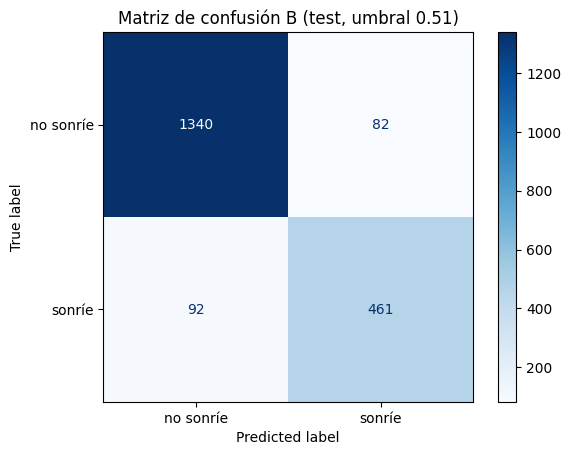

AUC test: 0.9622


In [7]:
# ==============================================================================
# 7. Selección del umbral óptimo de decisión mediante F1-Score en Validación
# ==============================================================================
# Mismo procedimiento riguroso que en Modelo A:
#   1. Búsqueda exhaustiva del umbral en el rango [0.10, 0.90] maximizando F1 en y_val.
#   2. np.argmax(f1s) determina el compromiso óptimo entre precisión y exhaustividad.
#   3. Evaluación final con classification_report, matriz de confusión y ROC-AUC en test.
p_val  = model.predict(X_val,  verbose=0).ravel()
p_test = model.predict(X_test, verbose=0).ravel()

thresholds = np.arange(0.10, 0.91, 0.01)
f1s = [f1_score(y_val, p_val >= t) for t in thresholds]
best_thr = float(thresholds[int(np.argmax(f1s))])
print(f"Mejor umbral (val): {best_thr:.2f} | F1 val: {max(f1s):.4f}")

for thr in (0.5, best_thr):
    pred = (p_test >= thr).astype(int)
    print(f"\n===== TEST con umbral {thr:.2f} =====")
    print(classification_report(y_test, pred, target_names=["no sonríe", "sonríe"],
                                digits=4, zero_division=0))

pred_best = (p_test >= best_thr).astype(int)
cm = confusion_matrix(y_test, pred_best)
ConfusionMatrixDisplay(cm, display_labels=["no sonríe", "sonríe"]).plot(cmap="Blues")
plt.title(f"Matriz de confusión B (test, umbral {best_thr:.2f})")
plt.savefig(f"{OUT}/B_confusion.png", dpi=130); plt.show()
auc = roc_auc_score(y_test, p_test)
print("AUC test:", round(auc, 4))


## 6. Velocidad de inferencia

In [8]:
# ==============================================================================
# 8. Medición de latencia de inferencia por rostro (Modelo B)
# ==============================================================================
sample = X_test[:1]
for _ in range(20): model(sample, training=False)
t0 = time.time()
for _ in range(200): model(sample, training=False)
ms = (time.time() - t0) / 200 * 1000
print(f"~{ms:.2f} ms por cara en este entorno")


~157.88 ms por cara en este entorno


## 7. Comparación con el Modelo A

In [9]:
# ==============================================================================
# 9. Comparación sistemática de rendimiento: Modelo A vs Modelo B
# ==============================================================================
# Valores del Modelo A tomados de su A_metrics.json (entrenamiento real)
A = {"accuracy": 0.9322, "f1": 0.8820, "auc": 0.9731, "ms": 25.25, "params": 296_097}
B = {"accuracy": float((pred_best == y_test).mean()), "f1": float(f1_score(y_test, pred_best)),
     "auc": float(auc), "ms": round(ms, 2), "params": model.count_params()}
print(f"{'':12s}{'Modelo A':>12s}{'Modelo B':>12s}")
for k, name in (("accuracy", "Accuracy"), ("f1", "F1 sonríe"), ("auc", "AUC"),
                ("ms", "ms/cara*"), ("params", "Parámetros")):
    fmt = (lambda v: f"{v:,}") if k == "params" else (lambda v: f"{v:.4f}" if k != "ms" else f"{v:.2f}")
    print(f"{name:12s}{fmt(A[k]):>12s}{fmt(B[k]):>12s}")
print("* los ms de cada modelo se midieron en sesiones distintas de Kaggle: orientativos. Mídanlos de nuevo en la laptop.")


                Modelo A    Modelo B
Accuracy          0.9322      0.9119
F1 sonríe         0.8820      0.8412
AUC               0.9731      0.9622
ms/cara*           25.25      157.88
Parámetros       296,097   2,259,265
* los ms de cada modelo se midieron en sesiones distintas de Kaggle: orientativos. Mídanlos de nuevo en la laptop.


## 8. Guardado

In [10]:
# ==============================================================================
# 10. Almacenamiento del modelo y exportación de métricas JSON
# ==============================================================================
model.save(f"{OUT}/model_B_mobilenetv2.keras")
metrics = {
    "modelo": "B_mobilenetv2_transfer_learning",
    "quick_test": QUICK_TEST,
    "epocas_cabeza": len(hist1.history["loss"]),
    "epocas_finetuning": len(hist2.history["loss"]),
    "minutos_entrenamiento": round(train_minutes, 2),
    "umbral_recomendado": best_thr,
    "test_accuracy": B["accuracy"], "test_f1_sonrie": B["f1"], "test_auc": B["auc"],
    "matriz_confusion": cm.tolist(),
    "ms_por_cara": B["ms"],
    "preprocesado": "gris, 64x64, float32 0-255, forma (1,64,64,1); resize 96 + 3 canales + [-1,1] dentro del modelo",
}
with open(f"{OUT}/B_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(json.dumps(metrics, indent=2, ensure_ascii=False))
print("\nArchivos en /kaggle/working:", os.listdir(OUT))


{
  "modelo": "B_mobilenetv2_transfer_learning",
  "quick_test": false,
  "epocas_cabeza": 10,
  "epocas_finetuning": 17,
  "minutos_entrenamiento": 2.62,
  "umbral_recomendado": 0.5099999999999998,
  "test_accuracy": 0.9118987341772152,
  "test_f1_sonrie": 0.8412408759124088,
  "test_auc": 0.9622020789301674,
  "matriz_confusion": [
    [
      1340,
      82
    ],
    [
      92,
      461
    ]
  ],
  "ms_por_cara": 157.88,
  "preprocesado": "gris, 64x64, float32 0-255, forma (1,64,64,1); resize 96 + 3 canales + [-1,1] dentro del modelo"
}

Archivos en /kaggle/working: ['model_B_mobilenetv2.keras', 'B_curvas.png', '__notebook__.ipynb', 'B_confusion.png', 'B_metrics.json']
